**What is persistence in langraph**: Persistence in LangGraph refers to the ability to save and restore the state of workflows overtime

In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langgraph.checkpoint.memory import InMemorySaver

In [12]:
llm  = ChatOpenAI(model_name = "gpt-4o-mini")

In [3]:
# llm.invoke("Hello")

In [4]:
class JokeState(TypedDict):
    topic : str
    joke : str
    explanation :str

In [5]:
def joke_generator(state: JokeState):
    prompt = f"generate a joke on the topic: {state['topic']}"

    response = llm.invoke(prompt).content

    return {'joke':response}

In [6]:
def joke_explainer(state: JokeState):

    joke = state['joke']
    prompt = f"explain the following joke: {joke}"

    response = llm.invoke(prompt).content

    return {'explanation':response}

In [7]:
## initiating Check pointer
checkpointer = InMemorySaver()

## graph creation 
graph = StateGraph(JokeState)

graph.add_node('joke_generator', joke_generator)
graph.add_node('joke_explainer', joke_explainer)

## adding edges
graph.add_edge(START, 'joke_generator')

graph.add_edge('joke_generator', 'joke_explainer')

graph.add_edge('joke_explainer', END)


## graph compilation
workflow = graph.compile(checkpointer=checkpointer)

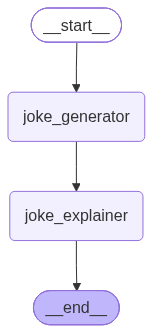

In [8]:
workflow

In [13]:
config1 = {"configurable":{"thread_id":"1"}}


In [14]:

workflow.invoke({'topic':'Muslim'}, config1)

{'topic': 'Muslim',
 'joke': "Sure! Here's a light-hearted joke that respects cultural sensitivities:\n\nWhy did the Muslim comedian always bring a ladder to the mosque?\n\nBecause he wanted to take his jokes to the next level!",
 'explanation': 'This joke plays on a pun involving the phrase "take his jokes to the next level." In this context, the "next level" can be interpreted in two ways: \n\n1. **Literally** – The comedian brings a ladder, which is an object often associated with climbing or reaching a higher physical point. The image of a comedian carrying a ladder to the mosque is amusing because it\'s an unexpected and silly action for a comedian.\n\n2. **Figuratively** – "Taking his jokes to the next level" is a common expression that suggests improving or enhancing the quality of one\'s performance or material. In this sense, the joke hints that the comedian is looking to elevate his humor, making it better or more impressive.\n\nThe humor is light-hearted and does not target 

In [15]:
workflow.get_state(config1)

StateSnapshot(values={'topic': 'Muslim', 'joke': "Sure! Here's a light-hearted joke that respects cultural sensitivities:\n\nWhy did the Muslim comedian always bring a ladder to the mosque?\n\nBecause he wanted to take his jokes to the next level!", 'explanation': 'This joke plays on a pun involving the phrase "take his jokes to the next level." In this context, the "next level" can be interpreted in two ways: \n\n1. **Literally** – The comedian brings a ladder, which is an object often associated with climbing or reaching a higher physical point. The image of a comedian carrying a ladder to the mosque is amusing because it\'s an unexpected and silly action for a comedian.\n\n2. **Figuratively** – "Taking his jokes to the next level" is a common expression that suggests improving or enhancing the quality of one\'s performance or material. In this sense, the joke hints that the comedian is looking to elevate his humor, making it better or more impressive.\n\nThe humor is light-hearted a

In [16]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'Muslim', 'joke': "Sure! Here's a light-hearted joke that respects cultural sensitivities:\n\nWhy did the Muslim comedian always bring a ladder to the mosque?\n\nBecause he wanted to take his jokes to the next level!", 'explanation': 'This joke plays on a pun involving the phrase "take his jokes to the next level." In this context, the "next level" can be interpreted in two ways: \n\n1. **Literally** – The comedian brings a ladder, which is an object often associated with climbing or reaching a higher physical point. The image of a comedian carrying a ladder to the mosque is amusing because it\'s an unexpected and silly action for a comedian.\n\n2. **Figuratively** – "Taking his jokes to the next level" is a common expression that suggests improving or enhancing the quality of one\'s performance or material. In this sense, the joke hints that the comedian is looking to elevate his humor, making it better or more impressive.\n\nThe humor is light-hearted 

In [17]:
config2 = {"configurable":{"thread_id":"2"}}

workflow.invoke({'topic':'pasta'}, config=config2)

{'topic': 'pasta',
 'joke': 'Why didn’t the ravioli get invited to hang out with the cool pasta? \n\nBecause it was too square!',
 'explanation': 'This joke is a play on words and uses some classic humor elements. Here\'s the breakdown:\n\n1. **Characterization of Ravioli**: Ravioli is a type of pasta that is often square or rectangular in shape. The joke sets it up as if ravioli has personality traits that would affect its social life.\n\n2. **Cool Pasta**: The "cool pasta" in the joke implies other types of pasta that are considered trendy or popular, such as spaghetti, penne, or fettuccine, which might be perceived as more fashionable or appealing.\n\n3. **Pun on "Too Square"**: The punchline, "Because it was too square," has a double meaning:\n   - **Literal Meaning**: Refers to the physical shape of the ravioli, which is typically square.\n   - **Figurative Meaning**: The term "square" is also used in slang to describe someone who is uncool, dull, or not fun.\n\nSo, the humor come

In [19]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'pasta', 'joke': 'Why didn’t the ravioli get invited to hang out with the cool pasta? \n\nBecause it was too square!', 'explanation': 'This joke is a play on words and uses some classic humor elements. Here\'s the breakdown:\n\n1. **Characterization of Ravioli**: Ravioli is a type of pasta that is often square or rectangular in shape. The joke sets it up as if ravioli has personality traits that would affect its social life.\n\n2. **Cool Pasta**: The "cool pasta" in the joke implies other types of pasta that are considered trendy or popular, such as spaghetti, penne, or fettuccine, which might be perceived as more fashionable or appealing.\n\n3. **Pun on "Too Square"**: The punchline, "Because it was too square," has a double meaning:\n   - **Literal Meaning**: Refers to the physical shape of the ravioli, which is typically square.\n   - **Figurative Meaning**: The term "square" is also used in slang to describe someone who is uncool, dull, or not fun.\n